# Exploring the LTEE reads

Questions: how long are the reads, and how does GC content vary between reads?
Exploration only: results that matter go into `reports/ltee-report.qmd`.

In [1]:
# Run from the project folder, like the scripts (lesson 02).
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd

samples = pd.read_csv("metadata/samples.tsv", sep="\t")
samples

,sample,strain,generation,population,mutator,cit,fastq_1,fastq_2
0,SRR2589044,REL2181A,5000,Ara-3,NaN,unknown,data/raw/fastq/SRR2589044_1.trim.sub.fastq,data/raw/fastq/SRR2589044_2.trim.sub.fastq
1,SRR2584863,REL7179B,15000,Ara-3,NaN,unknown,data/raw/fastq/SRR2584863_1.trim.sub.fastq,data/raw/fastq/SRR2584863_2.trim.sub.fastq
2,SRR2584866,REL11365,50000,Ara-3,plus,plus,data/raw/fastq/SRR2584866_1.trim.sub.fastq,data/raw/fastq/SRR2584866_2.trim.sub.fastq


In [2]:
# One row per read: sample, read length and GC content (first 5,000 reads of read 1).
# A FASTQ file has four lines per read; the second one is the sequence.
rows = []
for _, s in samples.iterrows():
    with open(s["fastq_1"]) as fh:
        for i, line in enumerate(fh):
            if i == 4 * 5000:
                break
            if i % 4 == 1:
                seq = line.strip()
                gc = 100 * (seq.count("G") + seq.count("C")) / len(seq)
                rows.append({"sample": s["sample"], "length": len(seq), "gc": gc})
reads = pd.DataFrame(rows)
reads.groupby("sample")[["length", "gc"]].describe().round(1)

length                                                     gc  \
             count   mean   std   min    25%    50%    75%    max   count   
sample                                                                      
SRR2584863  5000.0  130.3  31.2  25.0  107.0  150.0  150.0  150.0  5000.0   
SRR2584866  5000.0  128.3  36.1  25.0  113.8  150.0  150.0  150.0  5000.0   
SRR2589044  5000.0  130.0  31.4  26.0  108.0  150.0  150.0  150.0  5000.0   

                                                     
            mean  std   min   25%   50%   75%   max  
sample                                               
SRR2584863  50.8  6.9  20.8  47.3  51.5  55.3  74.4  
SRR2584866  51.0  7.0  24.0  47.3  51.7  55.3  78.6  
SRR2589044  50.8  7.0  20.0  47.0  51.9  55.3  77.8

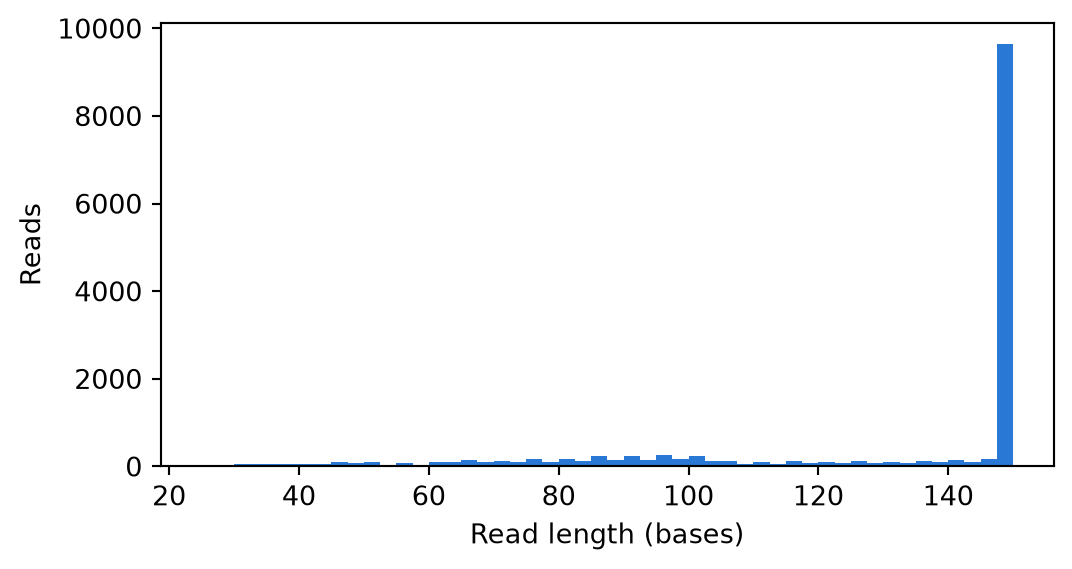

In [3]:
#| label: fig-lengths
#| fig-cap: "Read length after trimming, first 5,000 reads of read 1 of each sample."
#| fig-alt: "Histogram of read lengths from 25 to 150 bases. A single tall bar at 150 bases holds about 60 percent of the reads; the rest are spread thinly between 25 and 149 bases."
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(reads["length"], bins=50, color="#2a78d6")
ax.set_xlabel("Read length (bases)")
ax.set_ylabel("Reads")
plt.show()

About 60% of the reads are 150 bases long, the length of the sequencing run.
Trimming shortened the others, down to 25 bases, the shortest length that was kept.

In [4]:
# Share of reads shorter than 100 bases, per sample
(reads.assign(short=reads["length"] < 100)
      .groupby("sample")["short"].mean()
      .mul(100).round(1)
      .rename("% reads < 100 bases"))

sample
SRR2584863    21.0
SRR2584866    21.8
SRR2589044    21.4
Name: % reads < 100 bases, dtype: float64